In [1]:
import sys
sys.path.append('./src')
import scipy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# import equivariant steerable cnn
import escnn.gspaces
import escnn.nn

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import from_numpy
from sklearn.model_selection import train_test_split

from C3NN_extensions import C3NN_hybrid
from tqdm import tqdm
# Checking if you have a GPU and CUDA set up -- if not, training will take longer by running on the CPU
device = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.cuda.empty_cache()
random_seed = 1750
torch.manual_seed(random_seed)
#torch.backends.cudnn.benchmark = False
#torch.backends.cudnn.enabled = False

from sbi.inference import SNPE_C
from sbi import utils
from sbi.utils.get_nn_models import posterior_nn

from os import listdir
from os.path import isfile, join

from copy import deepcopy

#from getdist import MCSamples, plots

import pickle as pk
import cloudpickle as cldpk

from hyperparameters import hparams
from chainconsumer import ChainConsumer
import time, datetime

In [ ]:
from load_data import load_data_hybrid
params, data = load_data_hybrid(hparams)

In [17]:
data.size()

torch.Size([1250, 150, 5, 50, 50])

In [2]:
x_train = np.load('./data/2PCF_wide_realization0_mean.npy').reshape(1250, -1)


In [16]:
training_data.shape

torch.Size([1250, 150, 4, 50, 50])

In [2]:
compressed_2pt = np.load('./data/compressed_2pt.npy')
reshaped = torch.tensor(np.repeat(compressed_2pt,150,axis=0).reshape((1250,150,8)))

In [3]:
training_data = np.load('/project/ag-weller/Kai.Lehman/C3NN_data/kappa_noiseless_1250_wide_grid_cosmologies_150_maps_50_by_50pixels_6_by_6deg_no_smooth_4_des_zsbin_gnom_projection.npy')
training_data = torch.tensor(training_data, dtype=torch.float32)[:1250]

In [19]:
print(reshaped.shape)
padded = torch.cat((reshaped,torch.tensor(0).repeat((1250,150,50*50-8))),axis=2)
print(padded.shape)
padded_square = padded.reshape((1250,150,50,50)).unsqueeze(2)
print(padded_square.shape)

torch.Size([1250, 150, 8])
torch.Size([1250, 150, 2500])
torch.Size([1250, 150, 1, 50, 50])


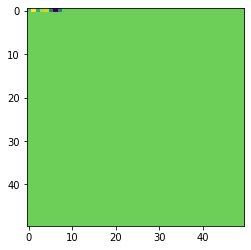

In [20]:
%matplotlib inline
plt.imshow(padded_square[0,0,0])
plt.show()

In [21]:
maps_and_2pt = torch.cat((training_data,padded_square),axis=2)

In [22]:
maps_and_2pt.shape

torch.Size([1250, 150, 5, 50, 50])

In [ ]:
from importlib import reload  
from torch.utils.data import TensorDataset, DataLoader
from src.C3NN_hybrid import C3NN_hybrid
from hyperparameters import hparams

In [45]:
import src.load_data
hparams.device='cpu'
reload(src.load_data)
params, data = src.load_data.load_data_hybrid(hparams)

In [56]:
dataset = TensorDataset(data, params)
loader = DataLoader(dataset, batch_size=7, shuffle=True,drop_last=True)

In [72]:
import src.C3NN_hybrid
reload(src.C3NN_hybrid)
hparams.num_filts = 2
model = src.C3NN_hybrid.C3NN_hybrid(hparams)

In [73]:
for x, y in loader:
    out = model(x)
    print(out.shape)
    break

torch.Size([7, 16])


In [81]:
print(out[0,-8:])
print(x[0,0,4,0,:8])
print(x[0,0,4,0,8:])

tensor([ 0.6302, -1.9519,  0.2872,  0.5981, -0.4831,  0.7880,  1.4037,  1.2242],
       grad_fn=<SliceBackward0>)
tensor([ 0.6302, -1.9519,  0.2872,  0.5981, -0.4831,  0.7880,  1.4037,  1.2242])
tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])


In [89]:
import torch.nn as nn
from torch import optim
device = 'cpu'

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(),lr=1e-3)

for x, y in loader:
    x, y = x.to(device), y.to(device)

    pred = model(x)
    loss = criterion(pred, y.repeat((1,2)))

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    break

In [96]:
from sbi.inference import SNPE_C
from sbi import utils
from sbi.utils.get_nn_models import posterior_nn
from torch import from_numpy
c3nn = C3NN_hybrid(hparams).to(device='cuda')
lower = np.array([0.1, 0.4, -2.0, 0.87, 0.03, 64.0, 12.0, -2.0])
upper = np.array([0.5, 1.4, -0.33, 1.07, 0.06, 82.0, 15.0, 2.0])
prior = utils.BoxUniform(low=from_numpy(lower), high=from_numpy(upper),device=hparams.device)
density_estimator_custom = posterior_nn(model="maf", hidden_features=hparams.flow_hidden_features, num_transforms=hparams.flow_num_transforms, num_blocks=hparams.num_blocks, device=hparams.device, embedding_net=c3nn)
inference = SNPE_C(prior, device=hparams.device, density_estimator=density_estimator_custom)
density_estimator = inference.append_simulations(params[:100], data[:100]).train(learning_rate=hparams.learning_rate, training_batch_size=hparams.flow_training_batch_size, max_num_epochs=2)#)300)

/home/k/Kai.Lehman/C3NN_inference/sbi/utils/user_input_checks.py:435: UserWarning: Mismatch between the device of the data fed to the embedding_net and the device of the embedding_net's weights. Fed data has device 'cpu' vs embedding_net weights have device 'cuda:0'. Automatically switching the embedding_net's device to 'cpu', which could otherwise be done manually using the line `embedding_net.to('cpu')`.
  warnings.warn(


torch.Size([1, 150, 5, 50, 50])
torch.Size([1, 50, 50])
torch.Size([1, 150, 4, 50, 50])
torch.Size([2, 150, 5, 50, 50])
torch.Size([2, 50, 50])
torch.Size([2, 150, 4, 50, 50])
torch.Size([32, 150, 5, 50, 50])
torch.Size([32, 50, 50])
torch.Size([32, 150, 4, 50, 50])
torch.Size([32, 150, 5, 50, 50])
torch.Size([32, 50, 50])
torch.Size([32, 150, 4, 50, 50])
torch.Size([10, 150, 5, 50, 50])
torch.Size([10, 50, 50])
torch.Size([10, 150, 4, 50, 50])
 Training neural network. Epochs trained: 1torch.Size([32, 150, 5, 50, 50])
torch.Size([32, 50, 50])
torch.Size([32, 150, 4, 50, 50])
torch.Size([32, 150, 5, 50, 50])
torch.Size([32, 50, 50])
torch.Size([32, 150, 4, 50, 50])
torch.Size([10, 150, 5, 50, 50])
torch.Size([10, 50, 50])
torch.Size([10, 150, 4, 50, 50])
 Training neural network. Epochs trained: 2torch.Size([32, 150, 5, 50, 50])
torch.Size([32, 50, 50])
torch.Size([32, 150, 4, 50, 50])
torch.Size([32, 150, 5, 50, 50])
torch.Size([32, 50, 50])
torch.Size([32, 150, 4, 50, 50])
torch.Size

In [4]:
# let's check the chain

#with open('/project/ag-weller/Kai.Lehman/C3NN_hybrid_inference/Models/inference.pickle', 'rb') as f:
#with open('/project/ag-weller/Kai.Lehman/C3NN_Models/order_4_filters_40_size_37_lr_1.00e-03_features_32_blocks_2_transforms_7_batchsize_16_hybrid_w_std_inference.pkl', 'rb') as f:
#with open('/project/ag-weller/Kai.Lehman/C3NN_Models/order_4_filters_20_size_37_lr_1.00e-03_features_32_blocks_2_transforms_7_batchsize_16_hybrid_w_std_inference.pkl', 'rb') as f:
#with open('/project/ag-weller/Kai.Lehman/C3NN_Models/order_4_filters_40_size_37_lr_1.00e-03_features_32_blocks_2_transforms_7_batchsize_16_hybrid_no2ptnorm_inference.pkl', 'rb') as f:
with open('/project/ag-weller/Kai.Lehman/C3NN_Models/order_4_filters_40_size_37_lr_1.00e-03_features_32_blocks_2_transforms_7_batchsize_16_hybrid_no2ptnorm_alldata_inference.pkl', 'rb') as f:
    inference_hybrid = cldpk.load(f)

In [5]:
#with open('/project/ag-weller/Kai.Lehman/C3NN_hybrid_inference/Models/density_estimator.pickle', 'rb') as f:
#with open('/project/ag-weller/Kai.Lehman/C3NN_Models/order_4_filters_40_size_37_lr_1.00e-03_features_32_blocks_2_transforms_7_batchsize_16_hybrid_w_std_density_estimator.pkl', 'rb') as f:
#with open('/project/ag-weller/Kai.Lehman/C3NN_Models/order_4_filters_20_size_37_lr_1.00e-03_features_32_blocks_2_transforms_7_batchsize_16_hybrid_w_std_density_estimator.pkl', 'rb') as f:
with open('/project/ag-weller/Kai.Lehman/C3NN_Models/order_4_filters_40_size_37_lr_1.00e-03_features_32_blocks_2_transforms_7_batchsize_16_hybrid_no2ptnorm_alldata_density_estimator.pkl', 'rb') as f:
    density_estimator_hybrid = cldpk.load(f)

In [6]:
compressed_2pt = np.load("./data/compressed_2pt_fid.npy")
reshaped = torch.tensor(np.repeat(compressed_2pt,150,axis=0).reshape((150,8)))
padded = torch.cat((reshaped,torch.tensor(0).repeat((150,50*50-8))),axis=1)
padded_square = padded.reshape((150,50,50)).unsqueeze(1).to('cuda')
print(padded_square.shape)
testing_data = np.load("/project/ag-weller/Kai.Lehman/C3NN_data/kappa_noiseless_fiducial_cosmology_150_maps_50_by_50pixels_6_by_6deg_no_smooth_4_des_zsbin_gnom_projection.npy")
testing_data = torch.tensor(testing_data, dtype=torch.float32).to(device='cuda')
print(testing_data.shape)
maps_and_2pt = torch.cat((testing_data,padded_square),axis=1)

torch.Size([150, 1, 50, 50])
torch.Size([150, 4, 50, 50])


In [56]:
help(density_estimator_hybrid.sample)

Help on method sample in module nflows.distributions.base:

sample(num_samples, context=None, batch_size=None) method of nflows.flows.base.Flow instance
    Generates samples from the distribution. Samples can be generated in batches.
    
    Args:
        num_samples: int, number of samples to generate.
        context: Tensor or None, conditioning variables. If None, the context is ignored.
        batch_size: int or None, number of samples per batch. If None, all samples are generated
            in one batch.
    
    Returns:
        A Tensor containing the samples, with shape [num_samples, ...] if context is None, or
        [context_size, num_samples, ...] if context is given.



In [69]:
summ = density_estimator_hybrid._embedding_net(maps_and_2pt.unsqueeze(0))

In [7]:
posterior_hybrid = inference_hybrid.build_posterior(density_estimator_hybrid)
samples_hybrid = posterior_hybrid.sample((1000000,), x=maps_and_2pt).cpu().numpy()

/home/k/Kai.Lehman/C3NN_inference/sbi/utils/torchutils.py:27: UserWarning: GPU was selected as a device for training the neural network. Note that we expect **no** significant speed ups in training for the default architectures we provide. Using the GPU will be effective only for large neural networks with operations that are fast on the GPU, e.g., for a CNN or RNN `embedding_net`.
  warnings.warn(


Drawing 1000000 posterior samples:   0%|          | 0/1000000 [00:00<?, ?it/s]

In [8]:
#sample_c2_nozscorex_bn_25filter = np.load('/project/ag-weller/Kai.Lehman/C3NN_Models/test_chains/25filters_2order_nozscorex_bn.npy')
sample_c2_nozscorex_bn_4filter = np.load('/project/ag-weller/Kai.Lehman/C3NN_Models/test_chains/4filters_2order_3d_nozscorex_bn_w_std.npy')
#sample_c3_nozscorex_bn_25filter_old = np.load('/project/ag-weller/Kai.Lehman/C3NN_Models/test_chains/25filters_3order_nozscorex_bn.npy')
sample_c3_nozscorex_bn_25filter = np.load('/project/ag-weller/Kai.Lehman/C3NN_Models/test_chains/25filters_3order_3d_nozscorex_bn_w_std.npy')
#sample_c4_nozscorex_bn_40filter = np.load('/project/ag-weller/Kai.Lehman/C3NN_Models/test_chains/40filters_4order_nozscorex_bn.npy')
sample_c4_nozscorex_bn_40filter = np.load('/project/ag-weller/Kai.Lehman/C3NN_Models/test_chains/40filters_4order_3d_nozscorex_bn_w_std_nocompression.npy')
samples_2PCF = np.load("./data/25latent_2PCF_samples.npy")[:,(0,1,2)]


In [11]:
parameter_cov_2 = np.cov(sample_c2_nozscorex_bn_4filter, rowvar=False)
parameter_cov_3 = np.cov(sample_c3_nozscorex_bn_25filter, rowvar=False)
parameter_cov_4 = np.cov(sample_c4_nozscorex_bn_40filter, rowvar=False)

In [14]:
posterior_FoM_2 = 1/np.sqrt(np.linalg.det(parameter_cov_2))
posterior_FoM_3 = 1/np.sqrt(np.linalg.det(parameter_cov_3))
posterior_FoM_4 = 1/np.sqrt(np.linalg.det(parameter_cov_4))

In [19]:
print(posterior_FoM_3/posterior_FoM_2 - 1)
print(posterior_FoM_4/posterior_FoM_3 - 1)

0.965949604871079
0.34376549161247993


In [ ]:
c3_std_improve[i,j] = np.sqrt(cov_c3[i,j,j])/np.sqrt(cov_c2[i,j,j]) - 1

np.sqrt(parameter)/np.sqrt(parameter_cov_2) - 1

In [9]:
c = ChainConsumer()
#c.add_chain(samples_hybrid, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, ..., c_4\}$ hybrid', shade=True, shade_alpha=0.1, color='orange', linestyle='-', linewidth=2.0, kde=False)
c.add_chain(samples_hybrid, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'$\{c_1, ..., c_4\}$ hybrid', shade=True, shade_alpha=0.1, color='orange', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(sample_c2_nozscorex_bn_25filter, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, c_2\}$ '+'25 filters no standardization plus BatchNorm', shade=True, shade_alpha=0.1, color='purple', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(sample_c3_nozscorex_bn_25filter, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, c_2, c_3\}$ '+'25 filters no standardization plus BatchNorm', shade=True, shade_alpha=0.3, color='b', linestyle='-', linewidth=2.0, kde=False)
c.add_chain(sample_c4_nozscorex_bn_40filter, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, \ldots, c_4\}$ '+'40 filters no standardization plus BatchNorm', shade=True, shade_alpha=0.7, color='green', linestyle='-', linewidth=2.0, kde=False)
c.add_chain(samples_2PCF, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'2PCF', shade=True, shade_alpha=0.7, color='red', linestyle='-', linewidth=2.0, kde=False)
c.configure_truth(linestyle='dotted', linewidth=0.5)
c.configure(label_font_size=20.0, tick_font_size=16.0, max_ticks=4, summary=False, spacing=2.0, legend_kwargs={'fontsize':14})
fig = c.plotter.plot(figsize=(12, 12), truth=[0.26, 0.84, -1, 0.9649, 0.0493, 67.3, 13.82, 0.0], legend=True)

AssertionError: Have only 3 columns in chain, but have been given 8 parameters names! Please double check this.

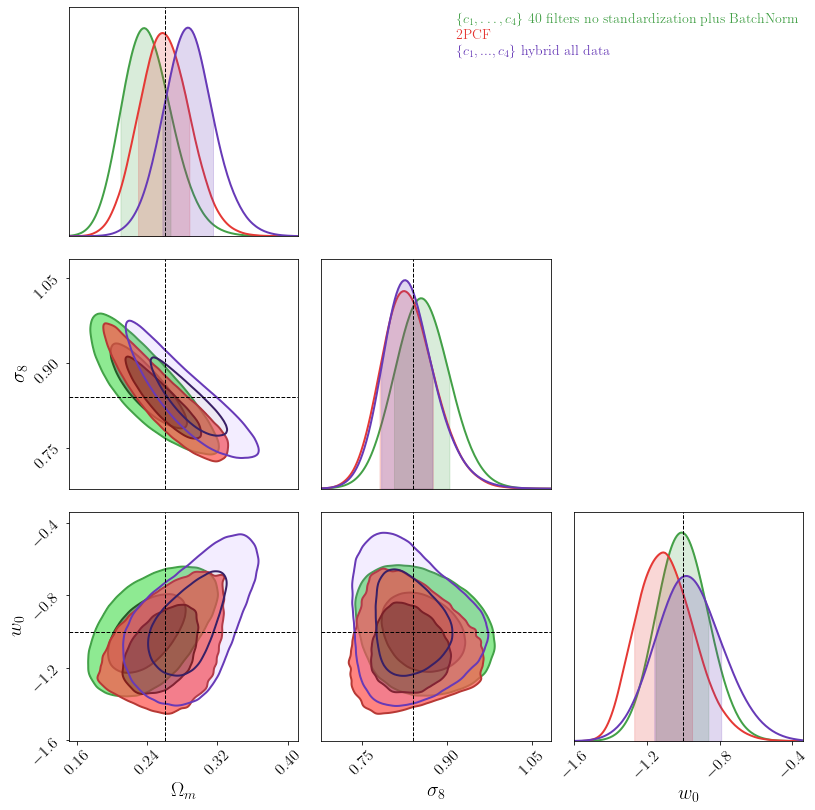

In [9]:
c = ChainConsumer()
#c.add_chain(sample_c4_nozscorex_bn_40filter[:,:3], parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'$\{c_1, \ldots, c_4\}$ '+'40 filters no standardization plus BatchNorm', shade=True, shade_alpha=0.7, color='green', linestyle='-', linewidth=2.0, kde=False)
c.add_chain(sample_c4_nozscorex_bn_40filter[:,:3], parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'$\{c_1, \ldots, c_4\}$ '+'40 filters no standardization plus BatchNorm', shade=True, shade_alpha=0.7, color='green', linestyle='-', linewidth=2.0, kde=False)
c.add_chain(samples_2PCF, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'2PCF', shade=True, shade_alpha=0.7, color='red', linestyle='-', linewidth=2.0, kde=False)
c.add_chain(samples_hybrid, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'$\{c_1, ..., c_4\}$ hybrid all data', shade=True, shade_alpha=0.1, color='purple', linestyle='-', linewidth=2.0, kde=False)
c.configure_truth(linestyle='dotted', linewidth=0.5)
c.configure(label_font_size=20.0, tick_font_size=16.0, max_ticks=4, summary=False, spacing=2.0, legend_kwargs={'fontsize':14})
fig = c.plotter.plot(figsize=(12, 12), truth=[0.26, 0.84, -1, 0.9649, 0.0493, 67.3, 13.82, 0.0], legend=True)
#plt.savefig('Plots/C3NN_hybrid_update.png',dpi=400)

In [81]:
'hello'

'hello'